# GCI World 2026 September – Final Assignment
## Reducing Customer Churn at a Telecom Operator: Handset-Aging & Contract-Cliff Retention Program
**Pipeline:** Data understanding → EDA → Hypothesis → Machine-learning model → Business proposal → Verification (profit simulation)

**Dataset:** `Client.csv` (customer/demographic/usage summary) + `Record.csv` (monthly behaviour averages + `churn` target), joined on `Customer_ID`.

## 0. Setup & data loading

In [ ]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)

# ---- Mount Google Drive (Colab) ------------------------------------------
# Adjust DATA_DIR to where you uploaded the "Final Assignment" folder in MyDrive.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/GCI_Global/Final Assignment/'   # <-- change if needed
except ImportError:                      # running locally
    DATA_DIR = os.environ.get('DATA_DIR', './')

os.makedirs('figures', exist_ok=True)
RESULTS = {}                             # numbers reused in the slides
client = pd.read_csv(DATA_DIR + 'Client.csv')
record = pd.read_csv(DATA_DIR + 'Record.csv')
print(client.shape, record.shape)

(100000, 50) (100000, 51)


In [ ]:
# Quick integrity checks, then join the two tables on Customer_ID
assert client.Customer_ID.is_unique and record.Customer_ID.is_unique
assert set(client.Customer_ID) == set(record.Customer_ID)
df = client.merge(record, on='Customer_ID', how='inner')
print('Merged shape:', df.shape, '| duplicated rows:', df.duplicated().sum())
df.head(3)

Merged shape: (100000, 100) | duplicated rows: 0


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,...,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,...,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.0,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,...,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.0,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,...,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.0,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58


## 1. Understanding the data & the target
* **Target:** `churn` (1 = customer left the operator).
* Client table: subscribers, revenue/minutes totals, handset info (`hnd_price`, `eqpdays` = *days the current equipment has been used*), household demographics.
* Record table: monthly averages of calls, drops, blocks, customer-care calls, plus change vs previous months (`change_mou`, `change_rev`) and tenure `months`.

In [ ]:
churn_rate = df.churn.mean()
RESULTS['n_customers'] = int(len(df)); RESULTS['churn_rate'] = float(churn_rate)
RESULTS['avg_monthly_rev'] = float(df.rev_Mean.mean())
print(f'Customers: {len(df):,} | churn rate: {churn_rate:.1%} | avg monthly revenue: ${df.rev_Mean.mean():.2f}')
miss = (df.isna().mean()*100).round(1); miss = miss[miss>0].sort_values(ascending=False)
print('\nColumns with missing values (%):'); print(miss.head(15))

Customers: 100,000 | churn rate: 49.6% | avg monthly revenue: $58.72



Columns with missing values (%):
numbcars            49.4
dwllsize            38.3
HHstatin            37.9
ownrent             33.7
dwlltype            31.9
lor                 30.2
income              25.4
adults              23.0
infobase            22.1
hnd_webcap          10.2
prizm_social_one     7.4
avg6qty              2.8
avg6mou              2.8
avg6rev              2.8
kid3_5               1.7
dtype: float64


Missing values are mostly demographic fields (≈1.7%–38%). They are **kept as missing** and handled inside the model pipeline (median imputation / `MISSING` category / native NaN support) rather than dropped, to avoid losing customers.

## 2. Exploratory data analysis – where does churn concentrate?

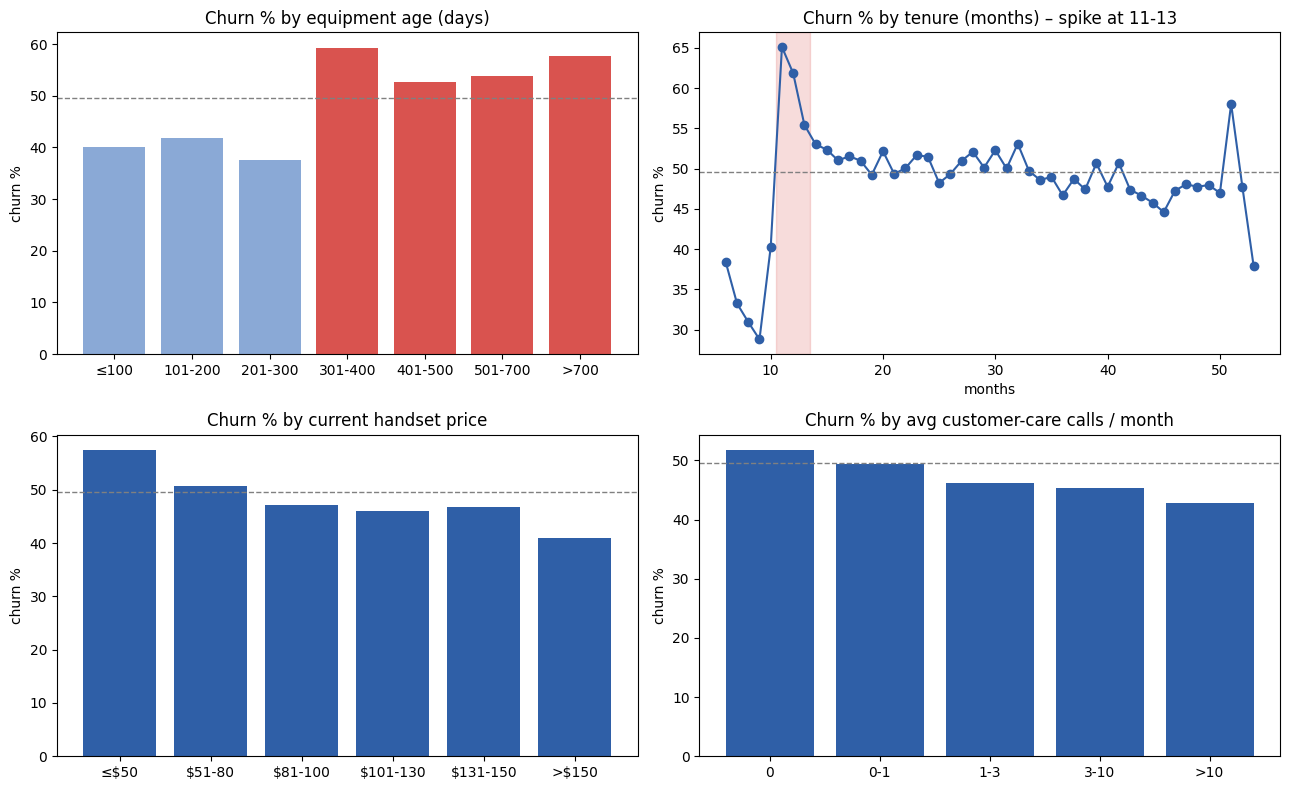

Equipment age ≤300d: 39.5% churn  vs  >300d: 56.3%  (60% of customers are >300d)
Tenure 6-10 months: 33.8%  vs  11-13 months: 61.4% (n=19,713)


In [ ]:
def rate_by(col, bins, labels=None):
    g = df.groupby(pd.cut(df[col], bins, labels=labels), observed=True).churn.agg(['mean','size'])
    g['mean'] *= 100; return g

eq   = rate_by('eqpdays', [-10,100,200,300,400,500,700,2000], ['≤100','101-200','201-300','301-400','401-500','501-700','>700'])
ten  = df.groupby('months').churn.agg(['mean','size']); ten = ten[ten['size']>=100]
hp   = rate_by('hnd_price', [0,50,80,100,130,150,500], ['≤$50','$51-80','$81-100','$101-130','$131-150','>$150'])
cc   = rate_by('custcare_Mean', [-1,0,1,3,10,1000], ['0','0-1','1-3','3-10','>10'])

fig, ax = plt.subplots(2,2, figsize=(13,8))
ax[0,0].bar(eq.index.astype(str), eq['mean'], color=['#8aa9d6']*3+['#d9534f']*4); ax[0,0].set_title('Churn % by equipment age (days)')
ax[0,1].plot(ten.index, ten['mean']*100, marker='o', color='#2f5fa7'); ax[0,1].axvspan(10.5,13.5,color='#d9534f',alpha=.2)
ax[0,1].set_title('Churn % by tenure (months) – spike at 11-13'); ax[0,1].set_xlabel('months')
ax[1,0].bar(hp.index.astype(str), hp['mean'], color='#2f5fa7'); ax[1,0].set_title('Churn % by current handset price')
ax[1,1].bar(cc.index.astype(str), cc['mean'], color='#2f5fa7'); ax[1,1].set_title('Churn % by avg customer-care calls / month')
for a in ax.ravel(): a.set_ylabel('churn %'); a.axhline(churn_rate*100, ls='--', c='grey', lw=1)
plt.tight_layout(); plt.savefig('figures/eda_drivers.png', dpi=150); plt.show()

old = df.eqpdays > 300
RESULTS['eq_bins'] = {k: round(v,1) for k,v in eq['mean'].items()}
RESULTS['eq_le300'] = float(df.churn[~old].mean()*100); RESULTS['eq_gt300'] = float(df.churn[old].mean()*100)
RESULTS['share_gt300'] = float(old.mean()*100)
RESULTS['tenure_11_13'] = float(df.churn[df.months.between(11,13)].mean()*100); RESULTS['n_tenure_11_13'] = int(df.months.between(11,13).sum())
RESULTS['tenure_6_10'] = float(df.churn[df.months.between(6,10)].mean()*100)
RESULTS['hp_bins'] = {k: round(v,1) for k,v in hp['mean'].items()}
RESULTS['cc_bins'] = {k: round(v,1) for k,v in cc['mean'].items()}
print(f"Equipment age ≤300d: {RESULTS['eq_le300']:.1f}% churn  vs  >300d: {RESULTS['eq_gt300']:.1f}%  ({RESULTS['share_gt300']:.0f}% of customers are >300d)")
print(f"Tenure 6-10 months: {RESULTS['tenure_6_10']:.1f}%  vs  11-13 months: {RESULTS['tenure_11_13']:.1f}% (n={RESULTS['n_tenure_11_13']:,})")

**Findings**
1. **Equipment age has a cliff at ≈300 days**: customers whose handset is older than ~300 days churn far more than those below it.
2. **Tenure shows a spike at months 11–13**, i.e. right when a first ~12-month commitment/handset subsidy typically ends; months 6–10 are the safest.
3. **Cheap handsets (≤$50) churn much more** than premium ones – low device investment = low switching cost.
4. **Customers who call customer care often churn *less*** – engaged/served customers stay; silent customers leave.
5. Declining usage (`change_mou` strongly negative) is an early-warning signal.

In [ ]:
# Interaction: handset age x tenure  (is the cliff just a tenure effect?)
pv = df.pivot_table(index=pd.cut(df.eqpdays,[-10,250,300,350,450,2000],labels=['≤250','251-300','301-350','351-450','>450']),
                    columns=pd.cut(df.months,[0,12,24,70],labels=['≤12m','13-24m','>24m']), values='churn', aggfunc='mean', observed=True)*100
print(pv.round(1))

months   ≤12m  13-24m  >24m
eqpdays                    
≤250     38.8    44.7  35.1
251-300  32.5    50.4  42.5
301-350  63.6    55.1  47.1
351-450  62.3    55.0  49.0
>450      NaN    53.9  56.6


The jump above ~300 days appears in **every** tenure group (largest for customers with ≤12 months tenure), so handset ageing is a driver on its own – not only a proxy for tenure.

## 3. Hypothesis

> **H:** Churn is triggered at the moment the customer's *handset ages past ~300 days / the first 12-month commitment ends*, especially for low-value handsets. If the operator **identifies these customers beforehand with an ML risk score** and offers a **timed handset-upgrade / loyalty offer**, churn among the targeted group can be reduced profitably.

Stakeholders: retention/CRM team (runs campaigns), sales & device-procurement (upgrade offers), finance (budget), customers.
Existing practice: untargeted mass discounts or retention calls *after* the customer asks to cancel → expensive and late.

## 4. Feature engineering & preprocessing

In [ ]:
from sklearn.model_selection import train_test_split
d = df.drop(columns=['Customer_ID']).copy()
d['eq_old_300']  = (d.eqpdays > 300).astype(int)
d['rev_per_min'] = d.rev_Mean / (d.mou_Mean + 1)
d['drop_rate']   = d.drop_vce_Mean / (d.plcd_vce_Mean + d.recv_vce_Mean + 1)
d['blk_rate']    = d.blck_vce_Mean / (d.plcd_vce_Mean + 1)
d['mou_trend']   = d.avg3mou / (d.avg6mou + 1)
d['idle_subs']   = d.uniqsubs - d.actvsubs
y = d.pop('churn'); X = d
cat = X.select_dtypes(exclude='number').columns.tolist(); num = X.select_dtypes('number').columns.tolist()
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(len(num),'numeric +',len(cat),'categorical features | train',X_tr.shape,'test',X_te.shape)

83 numeric + 21 categorical features | train (80000, 104) test (20000, 104)


## 5. Machine-learning models

                        AUC  Accuracy      F1
Model                                        
Logistic Regression  0.6496    0.6085  0.6118
Random Forest        0.6768    0.6256  0.6303
Gradient Boosting    0.6931    0.6382  0.6406


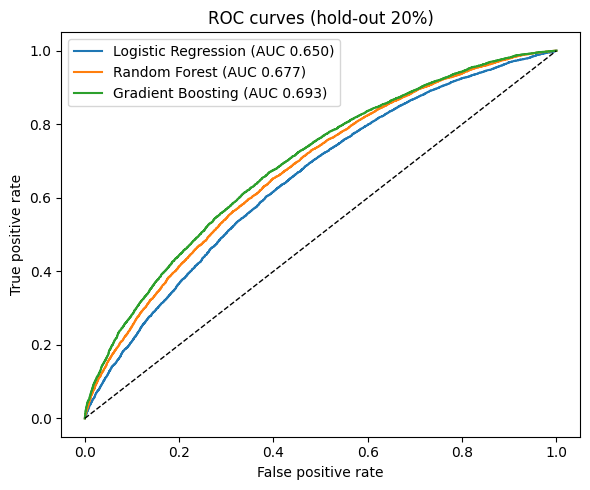

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, roc_curve

pre = ColumnTransformer([
    ('n', Pipeline([('i',SimpleImputer(strategy='median')),('s',StandardScaler())]), num),
    ('c', Pipeline([('i',SimpleImputer(strategy='constant',fill_value='MISSING')),
                    ('o',OneHotEncoder(handle_unknown='ignore',min_frequency=100))]), cat)])
models = {
 'Logistic Regression': Pipeline([('p',pre),('m',LogisticRegression(max_iter=500,C=0.1))]),
 'Random Forest':       Pipeline([('p',pre),('m',RandomForestClassifier(300,min_samples_leaf=20,n_jobs=-1,random_state=42))]),
}
# Gradient boosting handles NaN + categoricals natively
X_tr_h, X_te_h = X_tr.copy(), X_te.copy()
for c in cat:
    X_tr_h[c] = X_tr_h[c].astype('category'); X_te_h[c] = pd.Categorical(X_te_h[c], categories=X_tr_h[c].cat.categories)
hgb = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50,
                                     l2_regularization=1.0, categorical_features='from_dtype',
                                     early_stopping=True, random_state=42)
rows, probs = [], {}
for n,m in models.items():
    m.fit(X_tr, y_tr); probs[n] = m.predict_proba(X_te)[:,1]
hgb.fit(X_tr_h, y_tr); probs['Gradient Boosting'] = hgb.predict_proba(X_te_h)[:,1]
for n,p in probs.items():
    rows.append(dict(Model=n, AUC=roc_auc_score(y_te,p), Accuracy=accuracy_score(y_te,p>.5), F1=f1_score(y_te,p>.5)))
res = pd.DataFrame(rows).set_index('Model').round(4); print(res)
RESULTS['models'] = res.reset_index().to_dict('records')

plt.figure(figsize=(6,5))
for n,p in probs.items():
    f,t,_ = roc_curve(y_te,p); plt.plot(f,t,label=f'{n} (AUC {roc_auc_score(y_te,p):.3f})')
plt.plot([0,1],[0,1],'k--',lw=1); plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.legend(); plt.title('ROC curves (hold-out 20%)')
plt.tight_layout(); plt.savefig('figures/roc.png', dpi=150); plt.show()

Churn is intrinsically noisy (behavioural data only), so AUC ≈ 0.69 is realistic; the model is useful **for ranking** customers by risk. We check that below with a decile/lift analysis.

Churn in top-risk decile: 78.1%  |  lowest-risk decile: 19.6%  |  lift of top decile: 1.58x


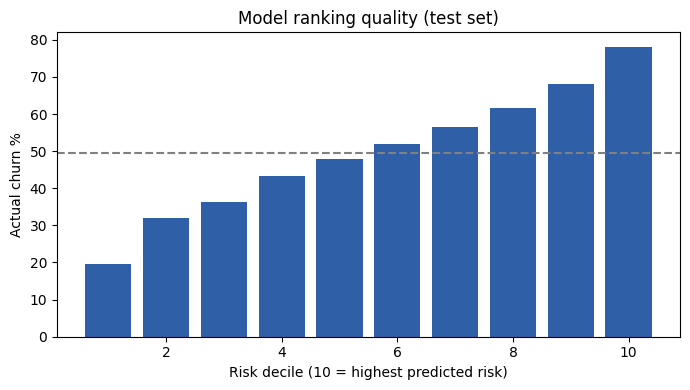

In [ ]:
p = probs['Gradient Boosting']
t = pd.DataFrame({'y':y_te.values,'p':p}); t['decile'] = pd.qcut(t.p.rank(method='first'),10,labels=range(1,11)).astype(int)
dec = t.groupby('decile').y.mean()*100
RESULTS['decile_churn'] = [round(v,1) for v in dec.values]
top, bot = dec.iloc[-1], dec.iloc[0]
print(f'Churn in top-risk decile: {top:.1f}%  |  lowest-risk decile: {bot:.1f}%  |  lift of top decile: {top/(churn_rate*100):.2f}x')
plt.figure(figsize=(7,4)); plt.bar(dec.index, dec.values, color='#2f5fa7'); plt.axhline(churn_rate*100,ls='--',c='grey')
plt.xlabel('Risk decile (10 = highest predicted risk)'); plt.ylabel('Actual churn %'); plt.title('Model ranking quality (test set)')
plt.tight_layout(); plt.savefig('figures/decile.png', dpi=150); plt.show()

months         0.0355
eqpdays        0.0337
change_mou     0.0308
totmrc_Mean    0.0132
hnd_price      0.0103
mou_trend      0.0085
avgqty         0.0085
rev_per_min    0.0076
crclscod       0.0059
area           0.0054
dtype: float64


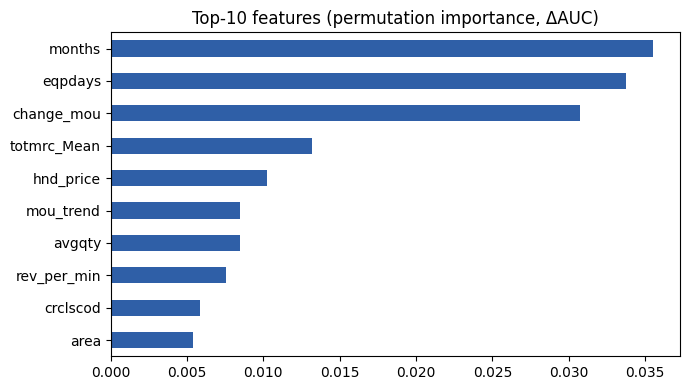

In [ ]:
from sklearn.inspection import permutation_importance
idx = np.random.RandomState(0).choice(len(X_te_h), 8000, replace=False)
pi = permutation_importance(hgb, X_te_h.iloc[idx], y_te.iloc[idx], scoring='roc_auc', n_repeats=3, random_state=0, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_te_h.columns).sort_values(ascending=False).head(10)
RESULTS['importance'] = {k: round(float(v),4) for k,v in imp.items()}
print(imp.round(4))
imp[::-1].plot.barh(figsize=(7,4), color='#2f5fa7'); plt.title('Top-10 features (permutation importance, ΔAUC)')
plt.tight_layout(); plt.savefig('figures/importance.png', dpi=150); plt.show()

Top drivers confirm the EDA: **tenure (`months`), equipment age (`eqpdays`), change in usage (`change_mou`), monthly recurring charge and handset price**.

## 6. Business proposal & verification

**Proposal – “Predict → Time → Offer”**
1. **Predict:** score every active customer monthly with the gradient-boosting model.
2. **Time:** trigger the campaign for high-risk customers approaching *handset age ≈ 250–300 days* / *tenure ≈ 10–11 months*, i.e. **before** the cliff.
3. **Offer:** handset-upgrade or loyalty offer (cost-controlled), prioritised by risk × customer value.

**Evaluation metric:** net profit of the campaign = (saved customers × customer value) − (customers contacted × offer cost). We verify it on the **hold-out test set using actual outcomes**, scaled to the full 100k customer base.

> ⚠ **Assumptions (not from the data – replace with the client's real figures):**
> * Contact cost = $2 per targeted customer (SMS/call).
> * Take-up of the offer = 20% of *all* targeted customers (churners and non-churners alike – non-churners who accept are a cost "leak"). A churner who accepts is **saved**.
> * Incentive (handset-upgrade subsidy) = $100, paid only when the offer is accepted.
> * Contribution margin = 40%; value of a saved customer = monthly revenue × margin × 12 months.

Best targeting share: top 70% of customers -> net profit ≈ $671,618 per campaign cycle
Targeting everyone (no model): net profit ≈ $547,743


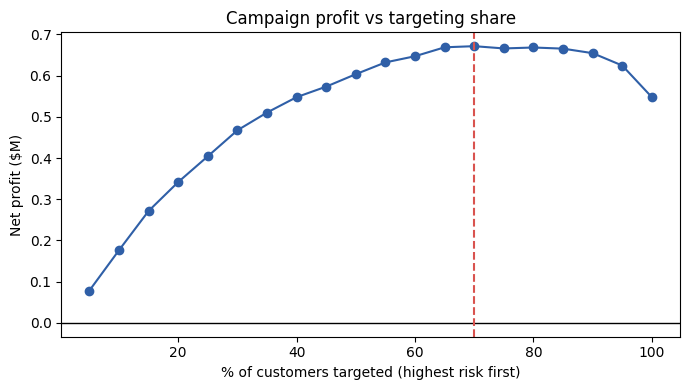

In [ ]:
TAKEUP, INCENTIVE, CONTACT, MARGIN, MONTHS_KEPT, SCALE = 0.20, 100.0, 2.0, 0.40, 12, 5   # SCALE: test set (20%) -> 100% of base

def campaign_profit(share, takeup=TAKEUP, incentive=INCENTIVE):
    k = int(len(t)*share); order = np.argsort(-t.p.values)[:k]
    rev = X_te.rev_Mean.fillna(X_te.rev_Mean.median()).values[order]
    saved_value = (t.y.values[order] * takeup * rev * MARGIN * MONTHS_KEPT).sum()   # churners who accept are saved
    cost = k*CONTACT + k*takeup*incentive                                             # everyone who accepts gets the incentive
    return (saved_value - cost) * SCALE

shares = np.arange(0.05, 1.0001, 0.05)
profit = np.array([campaign_profit(s) for s in shares])
best = shares[profit.argmax()]
RESULTS['profit_curve'] = {'shares': [round(float(s),2) for s in shares], 'profit': [round(float(v)) for v in profit]}
RESULTS['best_share'] = float(best); RESULTS['best_profit'] = float(profit.max()); RESULTS['all_profit'] = float(profit[-1])
print(f'Best targeting share: top {best:.0%} of customers -> net profit ≈ ${profit.max():,.0f} per campaign cycle')
print(f'Targeting everyone (no model): net profit ≈ ${profit[-1]:,.0f}')

plt.figure(figsize=(7,4)); plt.plot(shares*100, profit/1e6, marker='o', color='#2f5fa7'); plt.axhline(0,c='k',lw=1)
plt.axvline(best*100, ls='--', c='#d9534f'); plt.xlabel('% of customers targeted (highest risk first)'); plt.ylabel('Net profit ($M)')
plt.title('Campaign profit vs targeting share'); plt.tight_layout(); plt.savefig('figures/profit_curve.png', dpi=150); plt.show()

In [ ]:
# Sensitivity of the best-case profit to the two uncertain assumptions (take-up rate x incentive cost)
sens = pd.DataFrame({f'take-up {u:.0%}': [max(campaign_profit(sh, u, c) for sh in shares)/1e6 for c in (60,100,140)] for u in (0.10,0.20,0.30)},
                    index=[f'incentive ${c}' for c in (60,100,140)]).round(2)
RESULTS['sensitivity'] = {'index': list(sens.index), 'columns': list(sens.columns), 'values': sens.values.tolist()}
print('Max net profit ($M) per campaign cycle:'); print(sens)

Max net profit ($M) per campaign cycle:
                take-up 10%  take-up 20%  take-up 30%
incentive $60          0.60         1.38         2.17
incentive $100         0.27         0.67         1.08
incentive $140         0.08         0.23         0.38


In [ ]:
uplift = profit.max() - profit[-1]
print(f"Model-targeted campaign (top {best:.0%}): ${profit.max():,.0f} vs targeting everyone: ${profit[-1]:,.0f}  -> uplift ${uplift:,.0f}")
print("Scenarios with positive best-case profit:", int((sens.values>0).sum()), "of", sens.size)
RESULTS['uplift'] = float(uplift)

Model-targeted campaign (top 70%): $671,618 vs targeting everyone: $547,743  -> uplift $123,874
Scenarios with positive best-case profit: 9 of 9


**Conclusion**
* Because the churn rate in this dataset is ~50%, even contacting everyone is profitable under our assumptions (≈ $548K). The model adds value by **ranking who to contact**: the highest-risk decile churns ~4x more than the lowest (78% vs 20%), so each offer is spent where it can actually save someone.
* Best case is to target the top ~70% of customers (≈ $672K, **+$124K vs. contacting everyone**). A tighter campaign on only the top 30% still earns ≈ $467K (≈ 85% of the contact-everyone profit with 30% of the contacts) – useful if the retention budget is limited.
* Profit is positive in all 9 tested take-up / incentive scenarios, but ranges widely (≈ $0.08M to $2.2M) and depends on assumptions → **pilot first**: A/B test targeted vs control group to measure the real take-up before roll-out.

**Limitations / next steps:** churn rate here (~50%) suggests a balanced/re-sampled dataset, so absolute probabilities will differ on the live base; no contract-type or competitor-offer data; take-up, incentive and margin are assumptions; the model should be re-trained monthly and monitored for drift.

In [ ]:
with open('results.json','w') as f: json.dump(RESULTS, f, indent=1)
print('Saved results.json and figures/*.png')

Saved results.json and figures/*.png


## References
* Dataset: `Client.csv`, `Record.csv` provided by the GCI World course (Matsuo-Iwasawa Lab, UTokyo).
* The Value of Keeping the Right Customers, Harvard Business Review, 29 Oct 2014: https://hbr.org/2014/10/the-value-of-keeping-the-right-customers
* scikit-learn documentation – HistGradientBoostingClassifier, permutation_importance: https://scikit-learn.org/stable/
* Generative AI (Claude) used for analysis and code support – chat-history URL is listed in the submission form.
